<h1 align="center"> Assignment 1 </h1>
<h1 align="center">Agile Software Development</h1>
<h1 align="center">NYC_Airbnb_Data_Analysis_Sprint1</h1>

**Students:**

Baljeet Kaur,

Iheanacho, Precious

Martins Ronqui Miyajima, Paula

Zhu, Yaqun


**Project Overview**

This project is developed as part of the CPSC-620-3 Agile Software Development Take-Home Assessment.

The goal is to build a Python-based tool that reads, cleans, and summarizes NYC Airbnb listing data.

The project follows Agile development practices using GitHub and GitHub Projects.

**Sprint Goal**

Develop a functional Python-based NYC Airbnb Data Summary Tool that cleans and processes Airbnb listing data and generates meaningful summaries of listing prices, room types, neighbourhoods, and availability.

## Import libraries


In [1]:
import os
import sys
from pathlib import Path

project_path = Path(
    r"C:\Users\Precious Iheanacho\Desktop\MDA\Term 4\Agile Software\assignment 1\CPSC-620-3-Agile-Software-Development"
)

os.chdir(project_path)

if str(project_path) not in sys.path:
    sys.path.insert(0, str(project_path))

print("Project directory:", os.getcwd())
print("src exists:", (project_path / "src").exists())
print("data exists:", (project_path / "data").exists())

Project directory: C:\Users\Precious Iheanacho\Desktop\MDA\Term 4\Agile Software\assignment 1\CPSC-620-3-Agile-Software-Development
src exists: True
data exists: True


In [2]:
from src.data_cleaning import (
    load_data,
    clean_data,
    get_data_summary
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load clean dataset

In [4]:
data = load_data("data/Airbnb_NYC.csv")

cleaned_data = clean_data(data)

cleaned_data.head(2)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,20738991,Brownstone apartment in Bed-Stuy,37627534,Tim,Brooklyn,Bedford-Stuyvesant,40.68953,-73.93187,Private room,49.0,2.0,1,2017-09-11,0.05,1,0
1,10995810,Room in gorgeous Astoria Apartment,57055185,Halley,Queens,Astoria,40.76802,-73.91685,Private room,33.0,1.0,0,NaN,NaN,1,0



## 3.0 Histogram Distribution of Airbnb Nightly Prices

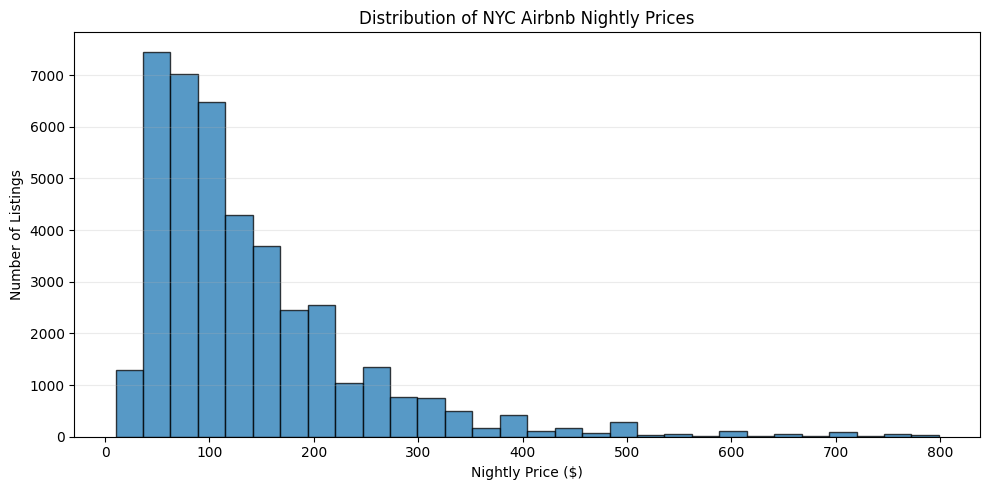

Common Price interval:
$36.30 to $62.60
Number of listings: 7456


In [5]:
import numpy as np
# chart limited to the 99th percentile for readability
price_limit = cleaned_data["price"].quantile(0.99)
prices = cleaned_data.loc[
    cleaned_data["price"] <= price_limit, "price"
]

# Analyze histogram data
bins = 30
counts, bin_edges = np.histogram(prices, bins=bins)

# Find the most common price interval
peak = np.argmax(counts)

# Create histogram
plt.figure(figsize=(10, 5))
plt.hist(prices, bins=bins, edgecolor="black", alpha=0.75)

# Add labels for readability
plt.title("Distribution of NYC Airbnb Nightly Prices")
plt.xlabel("Nightly Price ($)")
plt.ylabel("Number of Listings")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# Print results
print("Common Price interval:")
print(f"${bin_edges[peak]:.2f} to ${bin_edges[peak + 1]:.2f}")
print("Number of listings:", counts[peak])

## 3.0 Price Visualization Interpretation ##
This histogram excludes prices above 99th percentile for readability of the visaulization only. The cleaned dataset remain unchanged.
From the histogram chart, the distribution of NYC nightly prices are right skewed as listings are concentrated on the lower price ranges while the number of listings decreas as prices increases. The price range with the highest listing of 7417 are between $36.13 to $62.27, a small number of listings fall into higher price ranges( $300 to $800). This suggest that lower priced accomodation is more common in the dataset,although further analysis by room type and neighbourhood is needed to understand differences in pricing.


## 3.1 Listing by Room Type Visualization ##

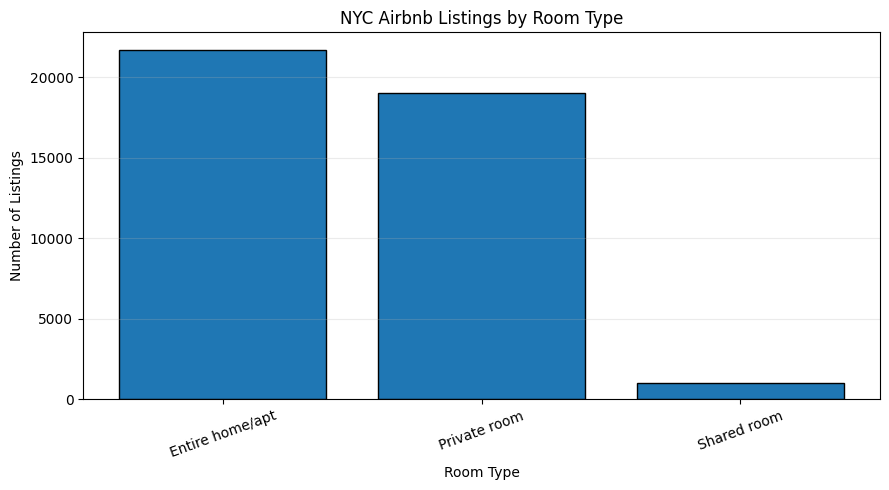

In [6]:
plt.figure(figsize=(9, 5))

room_counts = cleaned_data["room_type"].value_counts()

plt.bar(
    room_counts.index,
    room_counts.values,
    edgecolor="black")

plt.title("NYC Airbnb Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## 3.1 interpretation ##
The bar chart above shows that Entire home/apartment is the most common room type in Airbnb NYC  with approximately 22,000 listings while private room is the most second common room type with approximately 19,000 listings and shared room with only about 1000 listings. This suggest that Entire home/ apartment and private room dominate the Airbnb NYC market. This could also mean that there is low shared room availability  when compared to other room  types.


## 3.2 Average and median  Price comparison by Room Type ##

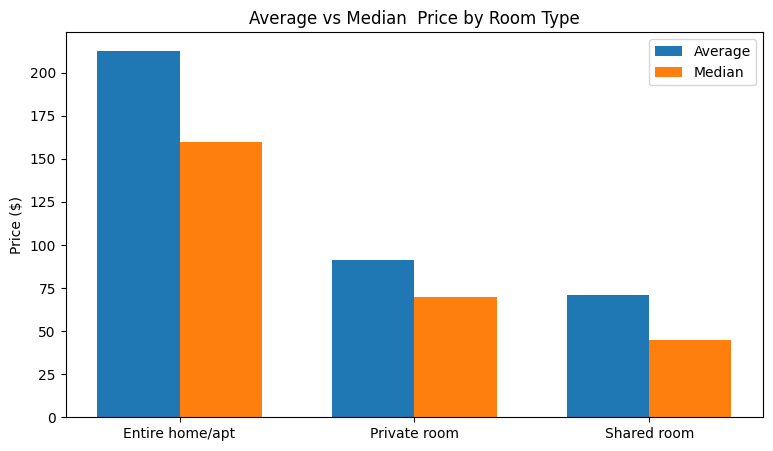

         room_type  Avg_Price  Median_Price
0  Entire home/apt  212.83113         160.0
1     Private room  91.006507          70.0
2      Shared room  70.720812          45.0


In [7]:
# average and median price by room type
price_by_room = (
    cleaned_data.groupby("room_type")
    .agg(
        Avg_Price=("price", "mean"),
        Median_Price=("price", "median")
    ).reset_index())

x = np.arange(len(price_by_room))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    price_by_room["Avg_Price"],
    width,
    label="Average")

plt.bar(
    x + width/2,
    price_by_room["Median_Price"],
    width,
    label="Median")

plt.xticks(x, price_by_room["room_type"])
plt.ylabel("Price ($)")
plt.title("Average vs Median  Price by Room Type")
plt.legend()

plt.show()
print(price_by_room)

## 3.2 Interpretation ##
The bar chart and table above showed that Entire home/apartment has the highest nightly price in Airbnb NYC with average price of $212.66 and median price of $160. While private room is more afforadable with average price of $89.40 and median price of $70, the shared room is the cheapest room type in Airbnb NYC with average price of $70.97 and median price of $45. The average prices of all room type is higher than the median price which confirmed the result of price distribution of the histogram that data is right skewed. This means that the high priced listings increases the average price within each room type.  Entire home and apartment has the highest prices than the other room type as reflected by the  average price and median price.

## 3.3 Listings in Common Price range by room type ##

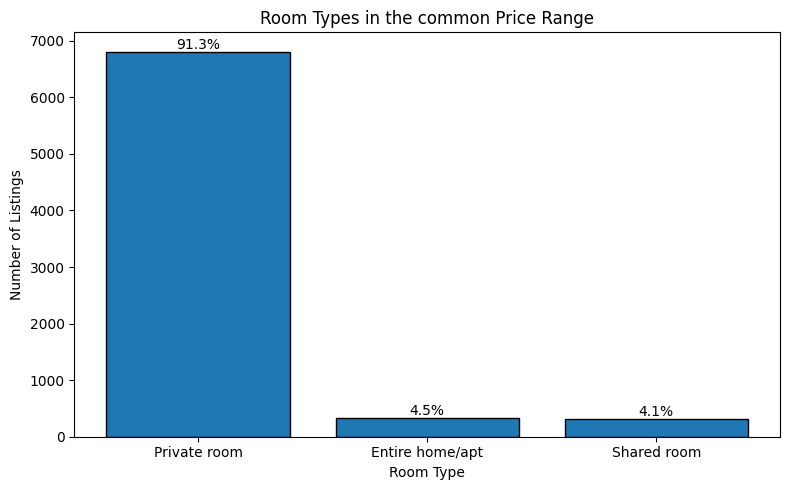

In [8]:
# Get the boundaries of the most common price interval
lower_bound = bin_edges[peak]
upper_bound = bin_edges[peak + 1]

# Select listings within that interval
peak_listings = cleaned_data[
    (cleaned_data["price"] >= lower_bound) &
    (cleaned_data["price"] < upper_bound)]

room_counts = peak_listings["room_type"].value_counts()

# Calculate percentages
percentages = room_counts / room_counts.sum() * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    room_counts.index,
    room_counts.values,
    edgecolor="black")

# Add percentage labels
for bar, pct in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha="center",
        va="bottom")

plt.title("Room Types in the common Price Range")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

## 3.3 Interpretation ##
Although the entire homes/apartments are the most common Airbnb room type overall but the most common price range of $36.13 to $62.27 is  dominated by private-room listings. 
91.3% of listings in this price range are private rooms, while entire homes/apartments and shared rooms each contribute less than 5%. This explains why the overall price distribution peaks at $36.13 to $62.27 despite entire homes/apartments having the highest overall listing count and much higher median and average prices.

## 3.4 Comparison of Average and Median Prices in NYC neigbourhood ##

,neighbourhood,total_listings,average_price,median_price
219,Tribeca,149,507.93,295.0
11,Battery Park City,60,393.93,177.5
85,Flatiron District,62,346.95,221.0
162,NoHo,62,302.73,250.0
104,Greenwich Village,342,298.42,199.0
200,SoHo,294,291.82,200.0
145,Midtown,1319,283.14,215.0
235,West Village,672,269.53,200.0
40,Chelsea,935,253.56,199.0
213,Theater District,238,237.34,187.0


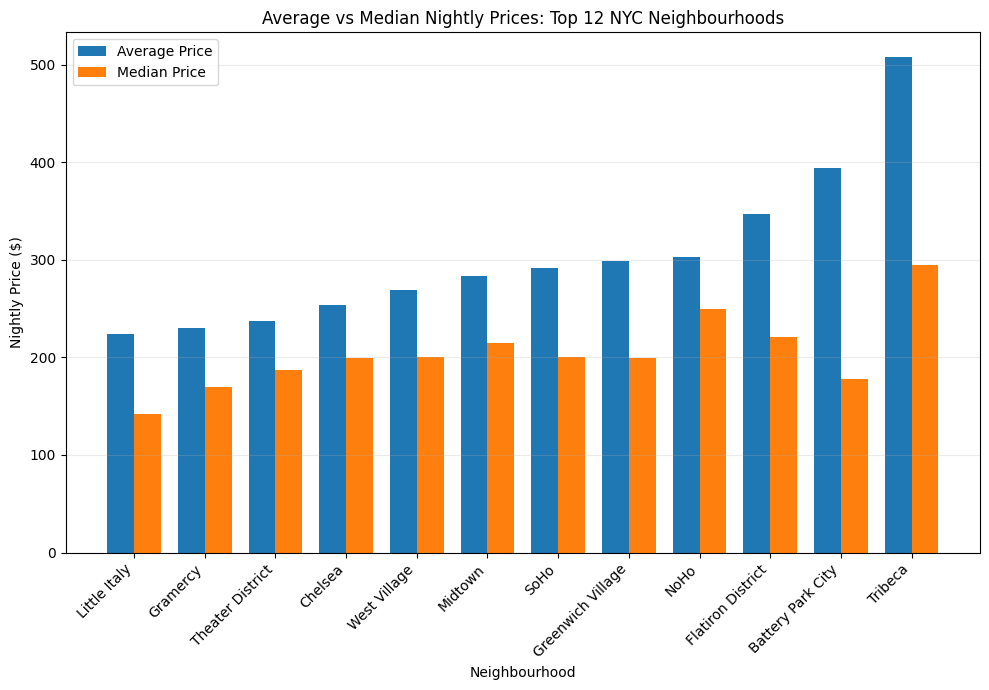

In [9]:

# New summary for comparing neighbourhood average and median prices

neighbourhood_price_comparison = (
    cleaned_data.groupby("neighbourhood")
    .agg(
        total_listings=("price", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median")
    ).reset_index())

# Apply the same minimum-listing requirement
neighbourhood_price_comparison = (
    neighbourhood_price_comparison[
        neighbourhood_price_comparison["total_listings"] >= 50
    ].copy())

# Round prices to 2 decimal places
neighbourhood_price_comparison["average_price"] = (
    neighbourhood_price_comparison["average_price"].round(2))

neighbourhood_price_comparison["median_price"] = (
    neighbourhood_price_comparison["median_price"].round(2))

# Select the 12 neighbourhoods with the highest average prices
top_12 = neighbourhood_price_comparison.nlargest(
    12, "average_price")

display(top_12)


# Sort for a clearer chart
top_12 = top_12.sort_values("average_price")

x = np.arange(len(top_12))
width = 0.38

plt.figure(figsize=(10, 7))

plt.bar(
    x - width / 2,
    top_12["average_price"],
    width,
    label="Average Price")

plt.bar(
    x + width / 2,
    top_12["median_price"],
    width,
    label="Median Price")

plt.xticks(x, top_12["neighbourhood"], rotation=45, ha="right")
plt.xlabel("Neighbourhood")
plt.ylabel("Nightly Price ($)")
plt.title("Average vs Median Nightly Prices: Top 12 NYC Neighbourhoods")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 3.4 Interpretation ##

The chart above compares the average and median nightly prices across the top 12 NYC neighbourhoods. In all neighbourhoods, the average price exceeds the median price indicating a positive skewed price distribution. 

Tribeca has the highest average nightly price of about $470, followed by Battery Park City of $400  and the Flatiron District ($350). Tribeca, Battery Park City and Flatiron District also have the largest gaps between average and median prices suggesting that high priced listings might be pulling the averages up athough additional analysis is needed to confirm this.Neighbourhoods such as Chelsea, West Village, and Midtown exhibit smaller differences between average and median prices, indicating more consistent pricing patterns.

Previous analysis revealed that entire home/apartments dominate the market but private rooms make up more than 90% of the listings  within the most common price range per night. This suggests that lower-priced listings are primarily concentrated among private rooms, whereas the  higher prices of entire-home accommodations contribute to higher neighbourhood averages, resulting in average prices exceeding median prices across neighbourhoods.

Median prices provide a more realistic representation of the typical nightly cost across neighbourhoods.

## 3.5 Neighourhood with the most Listing ##

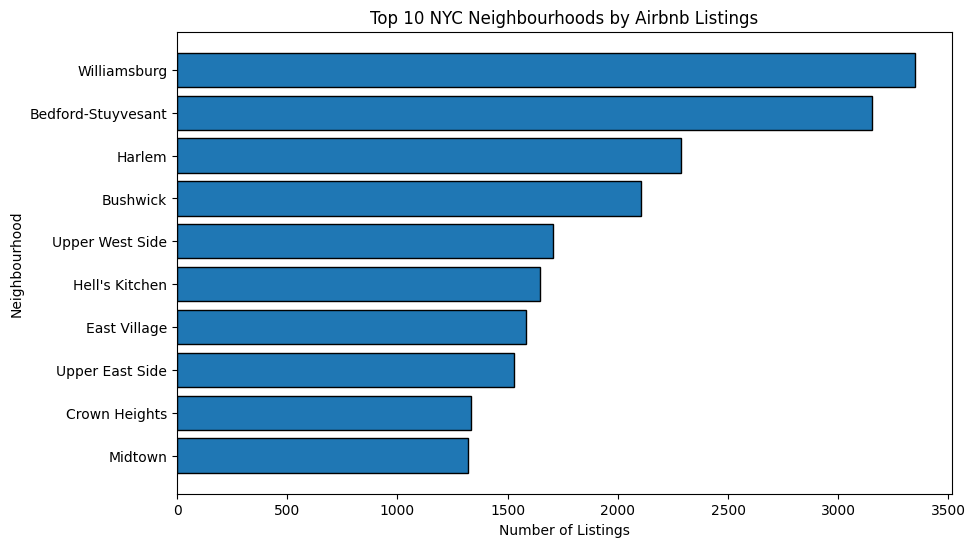

In [10]:
top_10_listings = (
    cleaned_data["neighbourhood"]
    .value_counts()
    .head(10)
    .sort_values())

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_listings.index,
    top_10_listings.values,
    edgecolor="black")

plt.title("Top 10 NYC Neighbourhoods by Airbnb Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")
plt.show()

### 3.5 Interpretation ##
The chart above shows the ten neighbourhoods with the highest number of Airbnb listing. Williamsburg has the largest concentration of listings with about 3,300 listings, followed by Bedford-Stuyvesant of about 3,100 listings while Harlem and Bushwick also have listings  over 2,000  each.

The remaining top 10 such as Upper West Side, Hell's Kitchen, East Village, Upper East Side, Crown Height and Midtown have between 1,300 to 1,700 listings. This suggest uneven distribution of the listing across neighbourhood with Williamsburg and Bedford-Stuyvesant serving as the largest supply hubs within the dataset.

## Interpretation of findings for business decision-making ##



##  Pricing Strategy

The price distribution shows that NYC Airbnb listings are concentrated within the lower price ranges. The most common price interval identified in the analysis was $36.13-$62.27, containing 7,417 listings. Private rooms accounted for 91.3% of the listings within this interval. However, entire homes and apartments recorded a higher average price of $212.66 and a median of $160, compared with $89.40 and $70 for private rooms.

This difference indicates that accommodation type is an important consideration when comparing listing prices. A private-room host may find it more useful to compare prices with similar private rooms rather than with entire apartments. Similarly, hosts offering entire homes should consider properties with comparable accommodation features when reviewing their pricing.

The difference between the average and median prices also suggests that some expensive listings influence the overall price distribution. Therefore, the median can provide a useful additional reference when examining typical listing prices.

### Business application ###
 Hosts and property managers could use these findings to establish more relevant price comparisons for their accommodation categories. However, the analysis does not identify the most profitable price because booking activity, operating expenses, and actual revenue were not included.

## Accommodation Type and Market Positioning

The accommodation analysis shows that entire homes and apartments represent the largest category, followed by private rooms and shared rooms. Entire homes and apartments account for approximately 22,000 listings, while private rooms account for approximately 19,000. Shared rooms have a considerably smaller representation, with approximately 1,000 listings.

The findings also show that accommodation categories differ in their price levels. Entire homes and apartments have higher average prices, while private and shared rooms appear more frequently in the lower price ranges. These differences provide useful information about how accommodation options are distributed across the market.

### Business application ###
 Property managers could use the accommodation distribution when reviewing their property offerings and marketing approaches. For example, private-room listings could be compared with other private rooms in the same area, while entire-home listings could be evaluated based on their location and property characteristics. This would allow businesses to develop more suitable positioning instead of treating all accommodation categories as one market.

The analysis does not establish the preferences of individual customers. Additional information about guest bookings and customer feedback would be required to determine which accommodation types are most attractive to different customer groups.

## Neighbourhood Pricing and Location Decisions

The neighbourhood analysis identifies differences in average nightly prices across New York City. Tribeca recorded an average price of approximately $470  and a median of $295. Battery Park City had an average price of $400 and a median price of $165  while Flatiron District recorded an average price of $350 and a median price of $221.

The differences between average and median prices indicate that neighbourhood pricing should be examined carefully. In Battery Park City, for example, the average is considerably higher than the median. This suggests that some listings may have higher prices than the typical listing in that area.

The listing-count analysis also identifies Williamsburg and Bedford-Stuyvesant as areas with substantial listing concentrations, with approximately 3,300 and 3,100 listings respectively. These areas therefore represent important locations for examining the distribution of Airbnb properties.

### Business application ###
 Property managers could compare neighbourhoods using both their listing prices and the number of available properties. A high average price may encourage further investigation of a neighbourhood's pricing structure, while a high listing count may indicate that more competitor comparisons are necessary.

However, these findings should not be interpreted as evidence that higher-priced neighbourhoods are more profitable or that neighbourhoods with many listings have stronger customer demand. Such decisions would require additional information about bookings, occupancy, property expenses, and local market conditions.

##  Marketing and Competitive Positioning

The distribution of listings across neighbourhoods and accommodation types provides an initial view of the Airbnb competitive environment. Williamsburg and Bedford-Stuyvesant have relatively high listing counts, while entire homes and private rooms account for most of the accommodation categories examined.

These patterns suggest that marketing decisions should consider the characteristics of individual properties and the surrounding market. Properties offering similar accommodation types may compete for comparable customers, making it important for hosts to communicate what distinguishes their listings.

For example, property managers could review the features, descriptions, and prices of comparable listings before deciding how to present their own properties. The analysis may also help identify neighbourhoods where further competitor research would be useful.

### Business application ###
 Hosts could use the findings to guide competitor comparisons and improve the way their properties are positioned. Marketing activities should be evaluated using actual performance measures, such as bookings, occupancy, customer feedback, and campaign results. Listing counts alone cannot determine which marketing approach will generate the best results.

##  Property Management and Inventory Planning

The analysis provides information about how Airbnb listings are distributed across accommodation categories and neighbourhoods. Entire homes and apartments represent the largest accommodation category, while private rooms also account for a substantial proportion of the listings. The neighbourhood analysis further shows that listing concentrations differ across locations.

These findings can support an initial review of the types of properties available in the market. However, the number of listings does not directly indicate whether a neighbourhood has too many or too few properties. A high listing count may reflect the size of the market rather than a shortage or excess of accommodation.

### Business application ###
 Property managers could use the listing distribution as a starting point when evaluating their current property portfolio or considering further market research. Before making investment or expansion decisions, they should examine booking patterns, occupancy rates, seasonal changes, operating costs, and applicable regulations.

This additional information would provide a stronger basis for determining whether a particular accommodation category or neighbourhood offers a suitable business opportunity.


The findings show that Airbnb listing prices and accommodation distributions differ across room types and neighbourhoods. Private rooms account for most listings in the most common price interval, while entire homes and apartments record higher average and median prices. The neighbourhood analysis also identifies differences in pricing and listing concentration.

These results can help property managers develop more relevant pricing comparisons, review their accommodation positioning, and identify locations for further competitor analysis. Using both average and median prices is particularly important when examining neighbourhoods where unusually expensive listings may influence the average.

Overall, the analysis provides a useful starting point for understanding the NYC Airbnb listing market. Nevertheless, further information about bookings, occupancy, seasonality, customer reviews, and operating expenses would be necessary to determine whether the observed patterns lead to stronger demand, higher revenue, or improved profitability.
